In [60]:
import torch
import torch.nn as nn

from torch.utils.data import TensorDataset, DataLoader

from sklearn.model_selection import train_test_split

import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

In [61]:
torch.manual_seed(1)

device = 'cuda' if torch.cuda.is_available() else 'cpu'
device

'cpu'

In [62]:
data = pd.read_csv('./data/processed/train.csv')

X = data.drop(columns=['Survived'])
y = data['Survived']

X['Embarked_Q'] = X['Embarked_Q'].astype(int)
X['Embarked_S'] = X['Embarked_S'].astype(int)

In [63]:
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

In [64]:
X_train = torch.tensor(X_train.values, dtype=torch.float32, device=device)
X_val = torch.tensor(X_val.values, dtype=torch.float32, device=device)
y_train = torch.tensor(y_train.values, dtype=torch.long, device=device)
y_val = torch.tensor(y_val.values, dtype=torch.long, device=device)

In [65]:
train_dataset = TensorDataset(X_train, y_train)
val_dataset = TensorDataset(X_val, y_val)

In [66]:
train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=16)


In [67]:
class TitanicClassifier(nn.Module):
    def __init__(self, input, output):
        super().__init__()
        self.layer = nn.Linear(input, output)
        
    def forward(self, x):
        out = self.layer(x)
        
        return out

model = TitanicClassifier(X_train.shape[1], 2).to(device)
model

TitanicClassifier(
  (layer): Linear(in_features=10, out_features=2, bias=True)
)

In [68]:
input = torch.rand([16, 10], dtype=torch.float32, device=device)

model(input).shape

torch.Size([16, 2])

In [69]:
loss_model = nn.CrossEntropyLoss()
opt = torch.optim.Adam(model.parameters(), lr=0.001)

In [70]:
# TODO: save best model

EPOCHS = 50
train_loss = []
train_acc = []
val_loss = []
val_acc = []
best_val_loss = float('inf')

for epoch in range(EPOCHS):
    model.train()
    true_answer = 0
    for x, targets in train_loader:
        pred = model(x)
        
        opt.zero_grad()
        
        loss = loss_model(pred, targets)
        loss.backward()
        opt.step()
        
        true_answer += (pred.argmax(dim=1) == targets).sum().item()
    
    model.eval()
    with torch.no_grad():
        train_pred = model(X_train)
        train_loss.append(loss_model(train_pred, y_train).item())
        train_acc.append((train_pred.argmax(dim=1) == y_train).float().mean().item())
        
        val_pred = model(X_val)
        
        loss = loss_model(val_pred, y_val)
    
        val_loss.append(loss.item())
        val_acc.append((val_pred.argmax(dim=1) == y_val).sum().item() / len(y_val))
    
        if loss < best_val_loss:
            best_val_loss = loss.item()
            
            torch.save(model.state_dict(), 'best_model.pt')
            print(f'model saved on {epoch + 1} epoch')
            

model saved on 1 epoch
model saved on 2 epoch
model saved on 3 epoch
model saved on 4 epoch
model saved on 5 epoch
model saved on 6 epoch
model saved on 7 epoch
model saved on 8 epoch
model saved on 9 epoch
model saved on 10 epoch
model saved on 11 epoch
model saved on 12 epoch
model saved on 13 epoch
model saved on 14 epoch
model saved on 15 epoch
model saved on 16 epoch
model saved on 17 epoch
model saved on 18 epoch
model saved on 19 epoch
model saved on 20 epoch
model saved on 21 epoch
model saved on 22 epoch
model saved on 23 epoch
model saved on 24 epoch
model saved on 25 epoch
model saved on 26 epoch
model saved on 27 epoch
model saved on 28 epoch
model saved on 29 epoch
model saved on 30 epoch
model saved on 31 epoch
model saved on 32 epoch
model saved on 33 epoch
model saved on 34 epoch
model saved on 35 epoch
model saved on 36 epoch
model saved on 37 epoch
model saved on 38 epoch
model saved on 39 epoch
model saved on 40 epoch
model saved on 41 epoch
model saved on 42 epoch
m

In [ ]:
test_data = pd.read_csv('./data/processed/test.csv')


,Pclass,Sex,Age,SibSp,Parch,Fare,FamilySize,IsAlone,Embarked_Q,Embarked_S
0,3,0,0.394887,0,0,-0.490783,1,1,True,False
1,3,1,1.355510,1,0,-0.507479,2,0,False,True
2,2,0,2.508257,0,0,-0.453367,1,1,True,False
3,3,0,-0.181487,0,0,-0.474005,1,1,False,True
4,3,1,-0.565736,1,1,-0.401017,3,0,False,True


In [ ]:
model.load_state_dict(
    torch.load('best_model.pt', map_location=device)
)
model.eval()

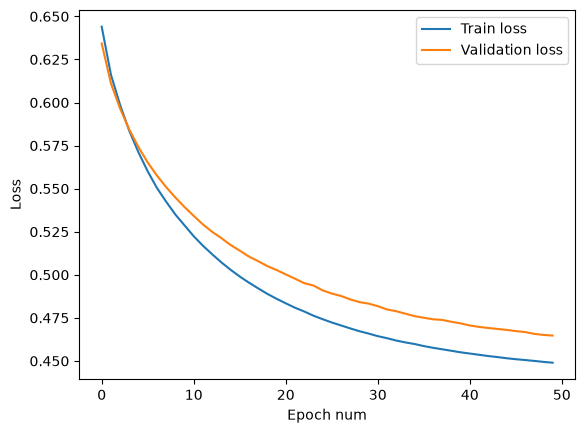

In [74]:
sns.lineplot(train_loss, label='Train loss')
sns.lineplot(val_loss, label='Validation loss')
plt.xlabel('Epoch num')
plt.ylabel('Loss');

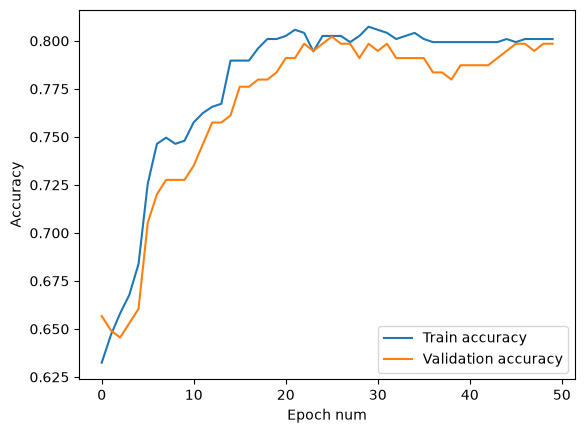

In [75]:
sns.lineplot(train_acc, label='Train accuracy')
sns.lineplot(val_acc, label='Validation accuracy')
plt.xlabel('Epoch num')
plt.ylabel('Accuracy');

In [76]:
print(train_acc[-1])
print(val_acc[-1])

0.8009631037712097
0.7985074626865671
